In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [5]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_50pthat1000_rc_truth.txt']

In [6]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
df = applyCut(df, 'pt>20')

In [8]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 674709
number of jets with q1 == +1: 929613


In [9]:
diquark_array = np.array([1103,2101,2103,2203,3101,3103,3201,3203,3303,4101,4103,4201,4203,4301,4303,4403,5101,5103,5201,\
                          5203,5301,5303,5401,5403,5503])

In [10]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    if (parent1 in diquark_array):
        parent1_new.append(-998)
    else:
        parent1_new.append(parent1)
    if (parent2 in diquark_array):
        parent2_new.append(-998)
    else:
        parent2_new.append(parent2)

In [11]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

Text(0.5, 0, 'invariant mass (leading,subleading) [GeV]')

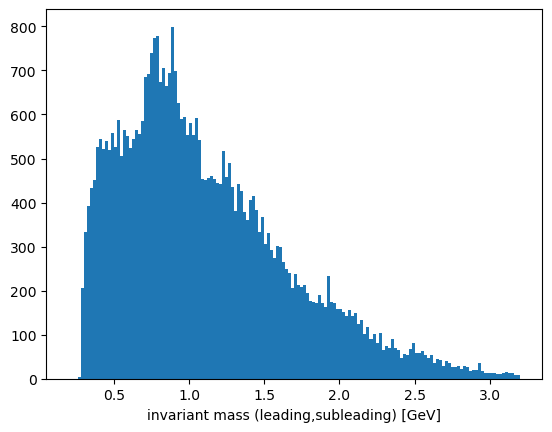

In [8]:
plt.hist(df['m'], weights=df['w'], bins=np.arange(0.2, 3.22, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')

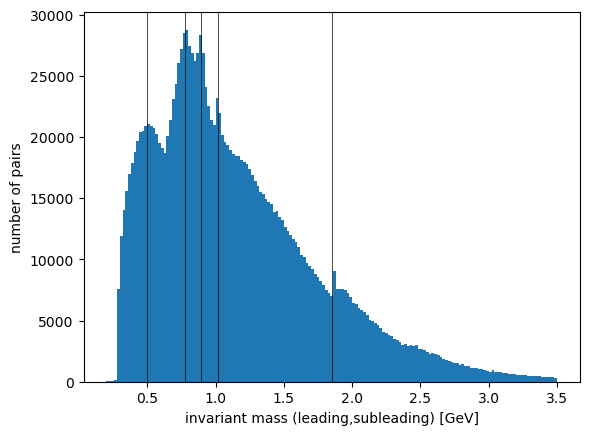

In [35]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [52]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998)]['w'])/sum(df['w']))

0.47258608705553873
0.5422025555561983


In [12]:
unique_parent1_new_array = np.unique(df['parent1_new'])
unique_parent2_new_array = np.unique(df['parent2_new'])

In [41]:
print(unique_parent1_new_array)

[ -20423  -20413  -20323  -20313  -20213  -10423  -10411  -10323  -10321
  -10313  -10311   -5232   -5132   -5122   -4332   -4232   -4224   -4222
   -4132   -4122   -4114   -4112   -3324   -3314   -3224   -3214   -3114
   -2224   -2214   -2114   -1114    -999    -998    -541    -531    -521
    -511    -435    -431    -425    -421    -413    -411    -325    -323
    -315    -313    -213     -15     -13     -11      11      13      15
     113     115     213     223     225     313     315     323     325
     331     333     411     413     415     421     425     431     435
     441     443     445     511     521     531     541    1114    2114
    2214    2224    3114    3214    3224    3314    3324    4112    4114
    4122    4132    4222    4224    4232    4332    5122    5132    5232
   10221   10311   10313   10321   10323   10413   10421   10423   10441
   20113   20213   20313   20413   20423   20443  100441 9000221 9010221]


In [13]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
print('subleading track pid: 211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_211[df_211.parent2_new==unique_parent2_new]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 211
subleading track parent pid: -999 , probability: 0.22122574973434833
subleading track parent pid: -998 , probability: 0.17797889379833914
subleading track parent pid: -313 , probability: 0.02054861428921826
subleading track parent pid: 113 , probability: 0.17198942443636459
subleading track parent pid: 213 , probability: 0.186510251693972
subleading track parent pid: 223 , probability: 0.1423098547477954
subleading track parent pid: 323 , probability: 0.03223549813654465


In [ ]:
# 113: rho0, 213: rho+, 223: omega, 313: K*0, 323: K*+

In [14]:
pid_array = []
prob_array = []
df_n211 = applyCut(df, 'pid2==-211')
print('subleading track pid: -211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n211[df_n211.parent2_new==unique_parent2_new]['w'])/sum(df_n211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -211
subleading track parent pid: -999 , probability: 0.21679320639977762
subleading track parent pid: -998 , probability: 0.17014259633778067
subleading track parent pid: -323 , probability: 0.03034753488115115
subleading track parent pid: -213 , probability: 0.19385723583758885
subleading track parent pid: 113 , probability: 0.1768338454208303
subleading track parent pid: 223 , probability: 0.13882480952489462
subleading track parent pid: 313 , probability: 0.028026725105381914


In [15]:
pid_array = []
prob_array = []
df_321 = applyCut(df, 'pid2==321')
print('subleading track pid: 321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_321[df_321.parent2_new==unique_parent2_new]['w'])/sum(df_321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 321
subleading track parent pid: -999 , probability: 0.3512293856772182
subleading track parent pid: -998 , probability: 0.2478743325166229
subleading track parent pid: -421 , probability: 0.027790151146323067
subleading track parent pid: 313 , probability: 0.2096543238358125
subleading track parent pid: 323 , probability: 0.10853360630517667
subleading track parent pid: 333 , probability: 0.03888752728540615


In [ ]:
# 313: K*0, 323: K*+, 333: phi, 421: D0

In [16]:
pid_array = []
prob_array = []
df_n321 = applyCut(df, 'pid2==-321')
print('subleading track pid: -321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n321[df_n321.parent2_new==unique_parent2_new]['w'])/sum(df_n321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -321
subleading track parent pid: -999 , probability: 0.3279436458257736
subleading track parent pid: -998 , probability: 0.2722605238420192
subleading track parent pid: -323 , probability: 0.11807999652746544
subleading track parent pid: -313 , probability: 0.19950715827200097
subleading track parent pid: 333 , probability: 0.038525852021358054
subleading track parent pid: 421 , probability: 0.03168520445553971


In [17]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid2==2212')
print('subleading track pid: 2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_2212[df_2212.parent2_new==unique_parent2_new]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 2212
subleading track parent pid: -999 , probability: 0.3592862254580544
subleading track parent pid: -998 , probability: 0.33038454516340915
subleading track parent pid: 2114 , probability: 0.04519772163954744
subleading track parent pid: 2214 , probability: 0.10470288769008457
subleading track parent pid: 2224 , probability: 0.15909123963108668


In [48]:
# 2114: Delta0, 2214: Delta+, 2224: Delta++

In [18]:
pid_array = []
prob_array = []
df_n2212 = applyCut(df, 'pid2==-2212')
print('subleading track pid: -2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n2212[df_n2212.parent2_new==unique_parent2_new]['w'])/sum(df_n2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -2212
subleading track parent pid: -2224 , probability: 0.14482120173709018
subleading track parent pid: -2214 , probability: 0.10299336931059473
subleading track parent pid: -2114 , probability: 0.04889162662083275
subleading track parent pid: -999 , probability: 0.39184756122869124
subleading track parent pid: -998 , probability: 0.3097939440924552


In [19]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    pid1 = df.iloc[i]['pid1']
    pid2 = df.iloc[i]['pid2']
    if ((abs(pid1) == 211 or abs(pid1) == 321) and (abs(parent1) == 213 or abs(parent1) == 323)): # sign preserving decay
        parent1_new.append(-997)
    elif (abs(pid1) == 2212 and (abs(parent1) == 2214 or abs(parent1) == 2224)):
        parent1_new.append(-997)
    else:
        parent1_new.append(parent1)
    if ((abs(pid2) == 211 or abs(pid2) == 321) and (abs(parent2) == 213 or abs(parent2) == 323)): # sign preserving decay
        parent2_new.append(-997)
    elif (abs(pid2) == 2212 and (abs(parent2) == 2214 or abs(parent2) == 2224)):
        parent2_new.append(-997)
    else:
        parent2_new.append(parent2)

([<matplotlib.patches.Wedge at 0x150355a889a0>,
 [Text(1.099999999999913, 4.376194920012509e-07, ''),
  Text(1.099999999988844, 4.954155851531412e-06, ''),
  Text(1.0999999736278976, 0.00024087055632744046, ''),
  Text(1.0999993696226202, 0.001177637396832823, ''),
  Text(1.0999983822022164, 0.0018865716277908322, ''),
  Text(1.0999983687842743, 0.001894379037078234, ''),
  Text(1.0999983619102391, 0.001898366347843318, ''),
  Text(1.099998221413975, 0.0019781016383776935, ''),
  Text(1.0999980557895939, 0.002068153551787949, ''),
  Text(1.0999979141091127, 0.00214218477290366, ''),
  Text(1.0999975618474165, 0.002316015919438213, ''),
  Text(1.0999973240032441, 0.002426352345010193, ''),
  Text(1.0999973213723857, 0.0024275447630309594, ''),
  Text(1.0999972193546241, 0.0024733402707891802, ''),
  Text(1.09999711808115, 0.0025179779912473162, ''),
  Text(1.0999971179701655, 0.002518026475185604, ''),
  Text(1.099997033585138, 0.0025546240226686657, ''),
  Text(1.0999968587373887, 0.00

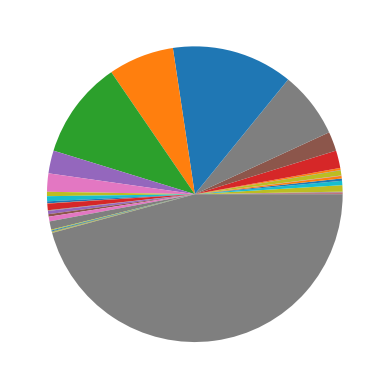

In [92]:
plt.pie(prob_array)

Text(0.5, 0, 'leading track $p_T$ [GeV]')

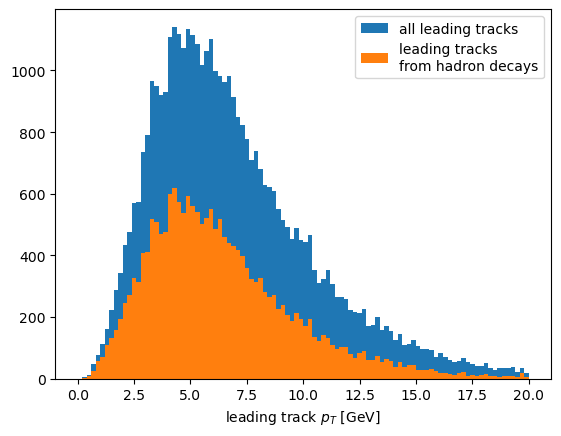

In [52]:
plt.hist(df['pt1'], weights=df['w'], bins=np.arange(0,20.2,0.2), label='all leading tracks')
plt.hist(df[df.parent1!=-999]['pt1'], weights=df[df.parent1!=-999]['w'], bins=np.arange(0,20.2,0.2), label='leading tracks\nfrom hadron decays')
plt.legend()
plt.xlabel('leading track $p_T$ [GeV]')

Text(0.5, 0, 'subleading track $p_T$ [GeV]')

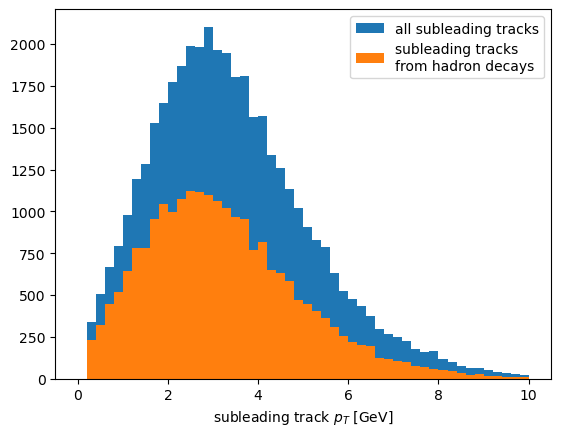

In [44]:
plt.hist(df['pt2'], weights=df['w'], bins=np.arange(0,10.2,0.2), label='all subleading tracks')
plt.hist(df[df.parent2!=-999]['pt2'], weights=df[df.parent2!=-999]['w'], bins=np.arange(0,10.2,0.2), label='subleading tracks\nfrom hadron decays')
plt.legend()
plt.xlabel('subleading track $p_T$ [GeV]')

In [30]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

In [31]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998) & (df.parent1_new!=-997)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998) & (df.parent2_new!=-997)]['w'])/sum(df['w']))

0.5017937728768326
0.5412312507693123


In [32]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998) & (df.parent2_new!=-997)]['w'])/sum(df['w']))

0.7044678126735633
0.5412312507693123


In [20]:
df.eval('b_ch = q1*q2', inplace=True)
df_twodiquark = applyCut(df, 'parent1_new==-998 and parent2_new==-998')
df_nondecay = applyCut(df, 'parent1==-999 and parent2==-999')
df_samesigndecay = applyCut(df, 'parent1==-997 and parent2==-997')
df_onedecay = applyCut(df, '(parent1!=-999 and parent2==-999) or (parent1==-999 and parent2!=-999)')
df_twodecay = applyCut(df, 'parent1!=-999 and parent2!=-999')

In [21]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [22]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [23]:
df_twodiquark_array = [ df_twodiquark[(df_twodiquark.pt>20) & (df_twodiquark.pt<25)],\
            df_twodiquark[(df_twodiquark.pt>25) & (df_twodiquark.pt<30)],\
            df_twodiquark[(df_twodiquark.pt>30) & (df_twodiquark.pt<40)] ]

In [24]:
twodiquark_rc_array = []
twodiquark_rc_err_array = []
for i in range(0, len(df_twodiquark_array)):
    twodiquark_rc_array.append(getRcAndErr(df_twodiquark_array[i], 'b_ch')[0])
    twodiquark_rc_err_array.append(getRcAndErr(df_twodiquark_array[i], 'b_ch')[1])

In [25]:
df_nondecay_array = [ df_nondecay[(df_nondecay.pt>20) & (df_nondecay.pt<25)],\
            df_nondecay[(df_nondecay.pt>25) & (df_nondecay.pt<30)],\
            df_nondecay[(df_nondecay.pt>30) & (df_nondecay.pt<40)] ]

In [26]:
nondecay_rc_array = []
nondecay_rc_err_array = []
for i in range(0, len(df_nondecay_array)):
    nondecay_rc_array.append(getRcAndErr(df_nondecay_array[i], 'b_ch')[0])
    nondecay_rc_err_array.append(getRcAndErr(df_nondecay_array[i], 'b_ch')[1])

In [27]:
df_samesigndecay_array = [ df_samesigndecay[(df_samesigndecay.pt>20) & (df_samesigndecay.pt<25)],\
            df_samesigndecay[(df_samesigndecay.pt>25) & (df_samesigndecay.pt<30)],\
            df_samesigndecay[(df_samesigndecay.pt>30) & (df_samesigndecay.pt<40)] ]

In [28]:
samesigndecay_rc_array = []
samesigndecay_rc_err_array = []
for i in range(0, len(df_samesigndecay_array)):
    samesigndecay_rc_array.append(getRcAndErr(df_samesigndecay_array[i], 'b_ch')[0])
    samesigndecay_rc_err_array.append(getRcAndErr(df_samesigndecay_array[i], 'b_ch')[1])

ZeroDivisionError: division by zero

In [29]:
df_onedecay_array = [ df_onedecay[(df_onedecay.pt>20) & (df_onedecay.pt<25)],\
            df_onedecay[(df_onedecay.pt>25) & (df_onedecay.pt<30)],\
            df_onedecay[(df_onedecay.pt>30) & (df_onedecay.pt<40)] ]

In [30]:
onedecay_rc_array = []
onedecay_rc_err_array = []
for i in range(0, len(df_onedecay_array)):
    onedecay_rc_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[0])
    onedecay_rc_err_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[1])

In [31]:
df_twodecay_array = [ df_twodecay[(df_twodecay.pt>20) & (df_twodecay.pt<25)],\
            df_twodecay[(df_twodecay.pt>25) & (df_twodecay.pt<30)],\
            df_twodecay[(df_twodecay.pt>30) & (df_twodecay.pt<40)] ]

In [32]:
twodecay_rc_array = []
twodecay_rc_err_array = []
for i in range(0, len(df_twodecay_array)):
    twodecay_rc_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[0])
    twodecay_rc_err_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[1])

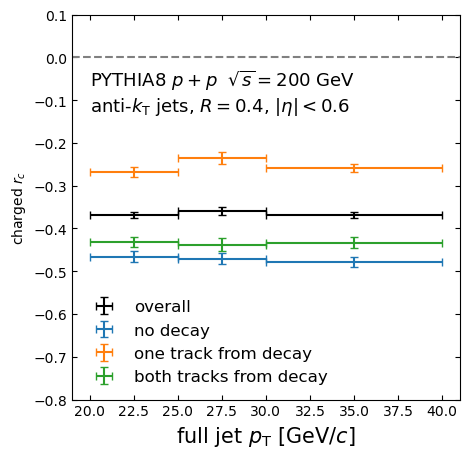

In [40]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.errorbar([22.5, 27.5, 35], nondecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nondecay_rc_err_array, capsize=3, ls='none', label='no decay')
plt.errorbar([22.5, 27.5, 35], onedecay_rc_array, xerr=[2.5, 2.5, 5], yerr=onedecay_rc_err_array, capsize=3, ls='none', label='one track from decay')
plt.errorbar([22.5, 27.5, 35], twodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=twodecay_rc_err_array, capsize=3, ls='none', label='both tracks from decay')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.125,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

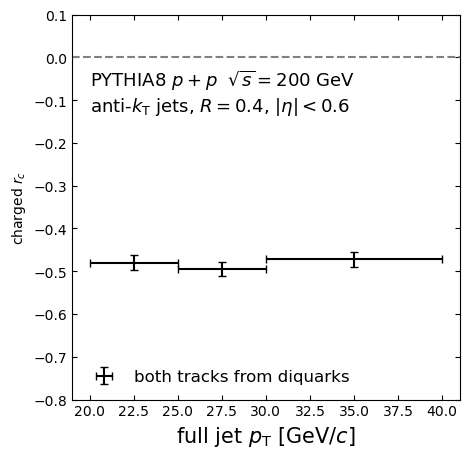

In [14]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], nondecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nondecay_rc_err_array, capsize=3, ls='none', label='no decay')
plt.errorbar([22.5, 27.5, 35], twodiquark_rc_array, xerr=[2.5, 2.5, 5], yerr=twodiquark_rc_err_array, capsize=3, ls='none', label='both tracks from diquarks')
plt.errorbar([22.5, 27.5, 35], samesigndecay_rc_array, xerr=[2.5, 2.5, 5], yerr=samesigndecay_rc_err_array, capsize=3, ls='none', label='both ')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.125,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')